#Assignment Task Overview
##Project Title: Social Media Engagement Analytics Using Python

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv('/content/social_media_engagement_5000.csv')
print(data)

      user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  Female     Brazil   496713     image       fitness   
1       10860  33.0    Male     Brazil   157326      reel          food   
2       86820  32.0  Female         UK   109864      text          food   
3       64886  51.0   Other     France   848877      text       fitness   
4       16265  34.0   Other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count   posted_at  \
0      7011.0     

#Assignment Tasks:
##Task 1 — Data Import & Setup

##Check/convert data types


In [ ]:
print(data.dtypes)

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [ ]:
print(data.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')


##Convert date columns to datetime

In [ ]:
data['posted_at'] = data['posted_at'].astype(str).str.strip()

In [ ]:
data['posted_at'] = pd.to_datetime(data['posted_at'], format='mixed', dayfirst= True, errors='coerce')

In [ ]:
print(data.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


#Task 2 — Data Cleaning
## Cleaning Missing Data
###Detect missing values (isnull(), isna())

In [ ]:
print(data.isnull())

      user_id    age  gender  country  post_id  post_type  post_category  \
0       False  False   False    False    False      False          False   
1       False  False   False    False    False      False          False   
2       False  False   False    False    False      False          False   
3       False  False   False    False    False      False          False   
4       False  False   False    False    False      False          False   
...       ...    ...     ...      ...      ...        ...            ...   
4995    False  False   False    False    False      False          False   
4996    False  False   False    False    False      False          False   
4997    False  False   False    False    False      False          False   
4998    False  False   False    False    False      False          False   
4999    False  False   False    False    False      False          False   

      likes  comments  shares  watch_time_sec  impression_count  posted_at  \
0     Fal

In [ ]:
print(data.isna())

      user_id    age  gender  country  post_id  post_type  post_category  \
0       False  False   False    False    False      False          False   
1       False  False   False    False    False      False          False   
2       False  False   False    False    False      False          False   
3       False  False   False    False    False      False          False   
4       False  False   False    False    False      False          False   
...       ...    ...     ...      ...      ...        ...            ...   
4995    False  False   False    False    False      False          False   
4996    False  False   False    False    False      False          False   
4997    False  False   False    False    False      False          False   
4998    False  False   False    False    False      False          False   
4999    False  False   False    False    False      False          False   

      likes  comments  shares  watch_time_sec  impression_count  posted_at  \
0     Fal

In [ ]:
print(data.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            4850 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             4850 non-null   float64       
 8   comments          4850 non-null   float64       
 9   shares            4850 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [ ]:
print(data.describe())

            user_id          age        post_id         likes     comments  \
count   5000.000000  4850.000000    5000.000000   4850.000000  4850.000000   
mean   54561.890800    38.454021  548042.909000  10107.043711  1502.195670   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5068.500000   760.000000   
50%    54374.500000    38.000000  548077.500000  10105.500000  1497.000000   
75%    77180.500000    51.000000  771574.500000  15115.000000  2256.000000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.912381  260646.957267   5789.819252   869.537889   

            shares  watch_time_sec  impression_count  \
count  4850.000000     5000.000000       5000.000000   
mean   1002.629485     4014.503200      50013.732800   
min       0.000000        0.000000        105.000000   
25%     498.000000     2017.750000      24988.250000   
50%    1012.00000

###Handle using: dropna(), fillna(), median/mode, forward/backward-fill

In [ ]:
data['age'] = data['age'].fillna(data['age'].median())
print(data)

      user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  Female     Brazil   496713     image       fitness   
1       10860  33.0    Male     Brazil   157326      reel          food   
2       86820  32.0  Female         UK   109864      text          food   
3       64886  51.0   Other     France   848877      text       fitness   
4       16265  34.0   Other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count  posted_at  \
0      7011.0     3

In [ ]:
data['gender']

,gender
0,Female
1,Male
2,Female
3,Other
4,Other
...,...
4995,Male
4996,Other
4997,Female
4998,Female


In [ ]:
gender_mode = data['gender'].mode()[0]
print(gender_mode)

Male


In [ ]:
data['gender']=data['gender'].str.strip()

In [ ]:
data['gender'] = data['gender'].bfill()

In [ ]:
data['gender']

,gender
0,Female
1,Male
2,Female
3,Other
4,Other
...,...
4995,Male
4996,Other
4997,Female
4998,Female


In [ ]:
data['likes'] = data['likes'].fillna(data['likes'].median())

In [ ]:
data['comments'] = data['comments'].fillna(data['comments'].median())

In [ ]:
data['shares'] = data['shares'].fillna(data['shares'].median())

In [ ]:
data['sentiment'] = data['sentiment'].fillna(data['sentiment'].mode()[0])

In [ ]:
print(data.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


Note:
The dataset does not contain any null values, so there is no need to use the "dropna()" method. The "dropna()" method is shown only as an example for handling missing values. It is not applied permanently to this dataset.

In [ ]:
data.dropna(subset='age')

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


data.dropna(subset=['age', 'gender'],inplace=True)

###Duplicate Handling- Identify & remove duplicates

In [ ]:
data.drop_duplicates()
data.duplicated().sum()

np.int64(0)

##● Data Formatting
###■ Fix incorrect data types

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [ ]:
data['age'] = data['age'].astype(int)

In [ ]:
data['likes'] = data['likes'].astype(int)

In [ ]:
data['comments'] = data['comments'].astype(int)

In [ ]:
data['shares'] = data['shares'].astype(int)

In [ ]:
print(data.dtypes)

user_id                      int64
age                          int64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


##Standardize categories (e.g., gender labels)

In [ ]:
data['gender'].unique()

array(['Female', 'Male', 'Other'], dtype=object)

In [ ]:
data['country'].unique()

array(['Brazil', 'UK', 'France', 'Canada', 'Japan', 'Australia', 'India',
       'UAE', 'Germany', 'USA'], dtype=object)

In [ ]:
data['post_type'].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

In [ ]:
data['post_type']=data['post_type'].str.strip().str.capitalize()

In [ ]:
data['device_type'].unique()

array(['mobile', 'tablet', 'desktop'], dtype=object)

In [ ]:
data['device_type'] = data['device_type'].str.strip().str.capitalize()

In [ ]:
data['sentiment'].unique()

array(['negative', 'positive', 'neutral'], dtype=object)

In [ ]:
data['sentiment'] = data['sentiment'].str.strip().str.capitalize()

In [ ]:
data['post_category'].unique()

array(['fitness', 'food', 'tech', 'travel', 'fashion', 'lifestyle',
       'education', 'music'], dtype=object)

In [ ]:
data['post_category'] = data['post_category'].str.strip().str.capitalize()

In [ ]:
data['gender'] = data['gender'].replace({'Male':'M', 'Female': 'F', 'Other': 'O'})

In [ ]:
data.columns = data.columns.str.capitalize()

In [ ]:
print(data)

      User_id  Age Gender    Country  Post_id Post_type Post_category  Likes  \
0       25795   43      F     Brazil   496713     Image       Fitness   7011   
1       10860   33      M     Brazil   157326      Reel          Food  11750   
2       86820   32      F         UK   109864      Text          Food   4862   
3       64886   51      O     France   848877      Text       Fitness   5350   
4       16265   34      O         UK   449706     Image       Fitness  12682   
...       ...  ...    ...        ...      ...       ...           ...    ...   
4995    59500   44      M  Australia   441541     Video     Education  16210   
4996    22100   38      O        UAE   677076      Reel     Education  16924   
4997    67021   63      F        USA   273595      Text        Travel  13487   
4998    29800   13      F    Germany   785644     Video       Fitness  16894   
4999    73400   54      O      Japan   712252      Text        Travel  14830   

      Comments  Shares  Watch_time_sec 

###■ Correct unrealistic values in likes, comments, shares

In [ ]:
data[(data['Likes']>=0) & (data['Comments']>=0) & (data['Shares']>=0)]

,User_id,Age,Gender,Country,Post_id,Post_type,Post_category,Likes,Comments,Shares,Watch_time_sec,Impression_count,Posted_at,Follower_count,Is_verified,Device_type,Sentiment,Hashtags,Engagement_rate
0,25795,43,F,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,M,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,F,UK,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,O,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,O,UK,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,M,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761
4996,22100,38,O,UAE,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155
4997,67021,63,F,USA,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688
4998,29800,13,F,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518


##Feature Cleaning
### Extract hashtag count

In [ ]:
data['Hashtag_count'] = data['Hashtags'].str.count('#')
print(data['Hashtag_count'])

0       3
1       1
2       1
3       3
4       1
       ..
4995    2
4996    2
4997    2
4998    3
4999    3
Name: Hashtag_count, Length: 5000, dtype: int64


###■ Clean sentiment labels

In [ ]:
data['Sentiment'].unique()

array(['Negative', 'Positive', 'Neutral'], dtype=object)

In [ ]:
data['Sentiment'] = data['Sentiment'].str.strip().str.upper()

In [ ]:
data['Sentiment'].value_counts()

,count
Sentiment,
POSITIVE,2513
NEUTRAL,1527
NEGATIVE,960


##Task 3 — Data Exploration using Pandas
###View dataset structure using head(), tail(), shape, and columns.
### Check data types and info with info() and dtypes.
###Generate summary statistics using describe().
###Analyze categorical distributions using value_counts(), unique(), and nunique().

In [ ]:
print(data.head())

   User_id  Age Gender Country  Post_id Post_type Post_category  Likes  \
0    25795   43      F  Brazil   496713     Image       Fitness   7011   
1    10860   33      M  Brazil   157326      Reel          Food  11750   
2    86820   32      F      UK   109864      Text          Food   4862   
3    64886   51      O  France   848877      Text       Fitness   5350   
4    16265   34      O      UK   449706     Image       Fitness  12682   

   Comments  Shares  Watch_time_sec  Impression_count  Posted_at  \
0       354    1157            5726             44650 2022-12-17   
1      2606    1807            5947             80216 2023-06-02   
2       344     955            6946             44858 2023-05-07   
3      1083    1049             229             70455 2023-02-12   
4      2735    1300            4798              6019 2023-05-23   

   Follower_count  Is_verified Device_type Sentiment               Hashtags  \
0           81734        False      Mobile  NEGATIVE  #foodie #trav

In [ ]:
print(data.tail())

      User_id  Age Gender    Country  Post_id Post_type Post_category  Likes  \
4995    59500   44      M  Australia   441541     Video     Education  16210   
4996    22100   38      O        UAE   677076      Reel     Education  16924   
4997    67021   63      F        USA   273595      Text        Travel  13487   
4998    29800   13      F    Germany   785644     Video       Fitness  16894   
4999    73400   54      O      Japan   712252      Text        Travel  14830   

      Comments  Shares  Watch_time_sec  Impression_count  Posted_at  \
4995      2013    1837            6190             42977 2022-06-25   
4996      2734    1583            7764             34196 2022-11-18   
4997      1497     167            7466             23680 2023-04-06   
4998      1289    1713            4991             89013 2022-05-16   
4999       503    1798            3743             14234 2023-03-04   

      Follower_count  Is_verified Device_type Sentiment  \
4995          646147        False

In [ ]:
print(data.shape)

(5000, 20)


In [ ]:
print(data.columns)

Index(['User_id', 'Age', 'Gender', 'Country', 'Post_id', 'Post_type',
       'Post_category', 'Likes', 'Comments', 'Shares', 'Watch_time_sec',
       'Impression_count', 'Posted_at', 'Follower_count', 'Is_verified',
       'Device_type', 'Sentiment', 'Hashtags', 'Engagement_rate',
       'Hashtag_count'],
      dtype='object')


In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   User_id           5000 non-null   int64         
 1   Age               5000 non-null   int64         
 2   Gender            5000 non-null   object        
 3   Country           5000 non-null   object        
 4   Post_id           5000 non-null   int64         
 5   Post_type         5000 non-null   object        
 6   Post_category     5000 non-null   object        
 7   Likes             5000 non-null   int64         
 8   Comments          5000 non-null   int64         
 9   Shares            5000 non-null   int64         
 10  Watch_time_sec    5000 non-null   int64         
 11  Impression_count  5000 non-null   int64         
 12  Posted_at         5000 non-null   datetime64[ns]
 13  Follower_count    5000 non-null   int64         
 14  Is_verified       5000 n

In [ ]:
print(data.dtypes)

User_id                      int64
Age                          int64
Gender                      object
Country                     object
Post_id                      int64
Post_type                   object
Post_category               object
Likes                        int64
Comments                     int64
Shares                       int64
Watch_time_sec               int64
Impression_count             int64
Posted_at           datetime64[ns]
Follower_count               int64
Is_verified                   bool
Device_type                 object
Sentiment                   object
Hashtags                    object
Engagement_rate            float64
Hashtag_count                int64
dtype: object


##Generate summary statistics using describe().

In [ ]:
print(data.describe())

            User_id          Age        Post_id         Likes     Comments  \
count   5000.000000  5000.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.440400  548042.909000  10106.982400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.000000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.687151  260646.957267   5702.293022   856.393312   

          Shares  Watch_time_sec  Impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   
50%    1012.0000     4034.5

In [ ]:
data.describe(include = 'object')

,Gender,Country,Post_type,Post_category,Device_type,Sentiment,Hashtags
count,5000,5000,5000,5000,5000,5000,5000
unique,3,10,4,8,3,3,761
top,M,India,Reel,Fitness,Mobile,POSITIVE,#tech
freq,1753,535,1283,675,1684,2513,201


##Analyze categorical distributions using value_counts(), unique(), and nunique().

In [ ]:
cate_col = ['Gender', 'Country', 'Post_type', 'Post_category', 'Device_type', 'Sentiment', 'Hashtags']
data[cate_col].value_counts()

Gender  Country    Post_type  Post_category  Device_type  Sentiment  Hashtags           
M       Japan      Image      Tech           Desktop      POSITIVE   #music                 3
O       Japan      Image      Lifestyle      Tablet       NEGATIVE   #music                 2
F       Australia  Video      Fitness        Mobile       POSITIVE   #lifestyle #fashion    2
M       Canada     Video      Tech           Desktop      POSITIVE   #love                  2
F       France     Reel       Education      Desktop      POSITIVE   #love                  2
                                                                                           ..
M       Australia  Image      Travel         Desktop      POSITIVE   #tech #foodie #love    1
                                                                     #reels                 1
                                                                     #love #fashion         1
                                                                     #fun #fashion #love    1
                   Reel       Fashion        Desktop      NEGATIVE   #fun #fashion          1
Name: count, Length: 4973, dtype: int64

In [ ]:
print(data['Gender'].value_counts())

Gender
M    1753
O    1625
F    1622
Name: count, dtype: int64


In [ ]:
print(data['Post_type'].value_counts())

Post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64


In [ ]:
print(data['Post_category'].value_counts())

Post_category
Fitness      675
Tech         665
Music        635
Education    631
Lifestyle    607
Travel       600
Fashion      594
Food         593
Name: count, dtype: int64


In [ ]:
print(data['Device_type'].value_counts())

Device_type
Mobile     1684
Tablet     1658
Desktop    1658
Name: count, dtype: int64


In [ ]:
print(data['Sentiment'].value_counts())

Sentiment
POSITIVE    2513
NEUTRAL     1527
NEGATIVE     960
Name: count, dtype: int64


In [ ]:
print(data['Hashtags'].value_counts())

Hashtags
#tech                     201
#love                     176
#fitness                  174
#music                    165
#fun                      163
                         ... 
#fun #foodie #reels         1
#love #tech #music          1
#love #lifestyle #tech      1
#reels #fun #foodie         1
#love #fashion #music       1
Name: count, Length: 761, dtype: int64


In [ ]:
print(data['Gender'].unique())

array(['F', 'M', 'O'], dtype=object)

In [ ]:
print(data['Gender'].nunique())

3


In [ ]:
print(data['Country'].unique())

array(['Brazil', 'UK', 'France', 'Canada', 'Japan', 'Australia', 'India',
       'UAE', 'Germany', 'USA'], dtype=object)

In [ ]:
print(data['Country'].nunique())

10

In [ ]:
print(data['Post_type'].unique())

array(['Image', 'Reel', 'Text', 'Video'], dtype=object)

In [ ]:
print(data['Post_type'].nunique())

4

In [ ]:
print(data['Post_category'].unique())

array(['Fitness', 'Food', 'Tech', 'Travel', 'Fashion', 'Lifestyle',
       'Education', 'Music'], dtype=object)

In [ ]:
print(data['Post_category'].nunique())

8

In [ ]:
print(data['Device_type'].unique())

array(['Mobile', 'Tablet', 'Desktop'], dtype=object)

In [ ]:
print(data['Device_type'].nunique())

3

In [ ]:
print(data['Sentiment'].unique())

array(['NEGATIVE', 'POSITIVE', 'NEUTRAL'], dtype=object)

In [ ]:
print(data['Sentiment'].nunique())

3

In [ ]:
print(data['Hashtags'].unique())

array(['#foodie #travel #love', '#fitness', '#foodie',
       '#music #foodie #fun', '#travel', '#music',
       '#travel #music #fitness', '#music #fun #fitness',
       '#lifestyle #love', '#tech', '#fun #fashion #love',
       '#foodie #lifestyle', '#foodie #fashion', '#reels',
       '#foodie #fun #lifestyle', '#love #fashion #fitness',
       '#foodie #travel #fitness', '#foodie #fitness', '#fun',
       '#reels #fashion', '#fashion', '#fitness #love',
       '#foodie #tech #fitness', '#love #music', '#love #foodie',
       '#lifestyle', '#fashion #fitness #reels', '#reels #tech',
       '#tech #fitness', '#music #lifestyle #love',
       '#lifestyle #fun #music', '#fitness #tech',
       '#reels #foodie #travel', '#tech #fun #foodie', '#fun #reels',
       '#love #music #travel', '#foodie #music #love',
       '#fashion #foodie #love', '#tech #reels', '#love',
       '#tech #music #foodie', '#love #music #fitness',
       '#travel #fashion #reels', '#love #fitness',
       '#food

In [ ]:
print(data['Hashtags'].nunique())

761


###Create a correlation matrix for numeric fields.

In [ ]:
num_col = ['Age', 'Likes', 'Comments', 'Shares', 'Watch_time_sec', 'Impression_count', 'Follower_count', 'Hashtag_count']
corr_matrix = data[num_col].corr()
print(corr_matrix)

                       Age     Likes  Comments    Shares  Watch_time_sec  \
Age               1.000000 -0.036323 -0.007284  0.013871        0.005542   
Likes            -0.036323  1.000000 -0.018421  0.004712        0.008710   
Comments         -0.007284 -0.018421  1.000000  0.006142       -0.016351   
Shares            0.013871  0.004712  0.006142  1.000000        0.014658   
Watch_time_sec    0.005542  0.008710 -0.016351  0.014658        1.000000   
Impression_count  0.013322  0.007952 -0.009395 -0.005204       -0.004335   
Follower_count   -0.024894 -0.022982 -0.011733 -0.010783        0.002761   
Hashtag_count     0.007173 -0.002190 -0.015230  0.013379       -0.023301   

                  Impression_count  Follower_count  Hashtag_count  
Age                       0.013322       -0.024894       0.007173  
Likes                     0.007952       -0.022982      -0.002190  
Comments                 -0.009395       -0.011733      -0.015230  
Shares                   -0.005204       -0

or

In [ ]:
cor_matrix = data.select_dtypes(include='number').corr()
print(cor_matrix)

                   User_id       Age   Post_id     Likes  Comments    Shares  \
User_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
Age              -0.006688  1.000000 -0.013153 -0.036323 -0.007284  0.013871   
Post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
Likes             0.025811 -0.036323  0.014526  1.000000 -0.018421  0.004712   
Comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
Shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
Watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
Impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
Follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
Engagement_rate  -0.004282  0.008039  0.010139  0.093521  0.000051  0.021724   
Hashtag_count    -0.013692  0.007173  0.007344 -0.002190 -0.015230  0.013379   

                  Watch_time_sec  Impre

###Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country.


In [ ]:
liked_posts = data.groupby('Post_type')['Likes'].mean()
print(liked_posts)

Post_type
Image    10104.852446
Reel     10037.784879
Text     10100.132530
Video    10188.586122
Name: Likes, dtype: float64


In [ ]:
country_wise_impression = data.groupby('Country')['Impression_count'].mean()
print(country_wise_impression)

Country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: Impression_count, dtype: float64


##Task 4 — Data Wrangling
###● Use merge, concat, or join if combining DataFrames.

Merge / Join / Concat: Not applicable because the given dataset contains all required information in a single DataFrame. Therefore, no separate DataFrames are available or required for merging or joining.

###Create new fields such as engagement_score, log-transformed metrics(optional), and hashtag count.


In [ ]:
data['engagement_score'] = data['Likes']+data['Comments']+data['Shares']
print(data['engagement_score'])

0        8522
1       16163
2        6161
3        7482
4       16717
        ...  
4995    20060
4996    21241
4997    15151
4998    19896
4999    17131
Name: engagement_score, Length: 5000, dtype: int64


In [ ]:
data['Hashtag_count'] = data['Hashtags'].fillna(data['Hashtags'].str.count('#'))
print(data['Hashtag_count'])

0             #foodie #travel #love
1                          #fitness
2                           #foodie
3               #music #foodie #fun
4                           #travel
                   ...             
4995                   #travel #fun
4996                 #foodie #reels
4997               #lifestyle #tech
4998          #reels #love #fitness
4999    #foodie #lifestyle #fashion
Name: Hashtag_count, Length: 5000, dtype: object


###Perform groupby summaries by post_type, country, and sentiment.

In [ ]:
print(data.groupby('Post_type')['engagement_score'].mean().reset_index())
print(data.groupby('Country')['engagement_score'].mean().reset_index())
print(data.groupby('Sentiment')['engagement_score'].mean().reset_index())

  Post_type  engagement_score
0     Image      12649.377706
1      Reel      12524.014030
2      Text      12613.228112
3     Video      12664.580408
     Country  engagement_score
0  Australia      12809.604462
1     Brazil      12385.972222
2     Canada      12605.883041
3     France      12903.370968
4    Germany      12635.640816
5      India      12492.678505
6      Japan      12578.637712
7        UAE      12757.763419
8         UK      12384.361055
9        USA      12575.449102
  Sentiment  engagement_score
0  NEGATIVE      12731.483333
1   NEUTRAL      12448.149312
2  POSITIVE      12665.784322


#❖ Task 5 — Statistical Analysis
##Compute descriptive stats for “likes, comments, shares, watch_time,engagement_rate, followers” columns:


###Mean, median, mode

In [ ]:
columns = [ 'Likes', 'Comments', 'Shares', 'Watch_time_sec', 'Engagement_rate', 'Follower_count' ]

In [ ]:
data[columns].mean()

,0
Likes,10106.982400
Comments,1502.039800
Shares,1002.910600
Watch_time_sec,4014.503200
Engagement_rate,0.964356
Follower_count,393698.224800


In [ ]:
data[columns].median()

,0
Likes,10105.000000
Comments,1497.000000
Shares,1012.000000
Watch_time_sec,4034.500000
Engagement_rate,0.253896
Follower_count,388982.000000


In [ ]:
data[columns].mode().iloc[0]

,0
Likes,10105.000000
Comments,1497.000000
Shares,1012.000000
Watch_time_sec,916.000000
Engagement_rate,0.006363
Follower_count,497502.000000


###Standard deviation, variance

In [ ]:
data[columns].std()

,0
Likes,5702.293022
Comments,856.393312
Shares,570.855200
Watch_time_sec,2308.096459
Engagement_rate,5.318029
Follower_count,230927.884535


In [ ]:
data[columns].var()

,0
Likes,3.251615e+07
Comments,7.334095e+05
Shares,3.258757e+05
Watch_time_sec,5.327309e+06
Engagement_rate,2.828143e+01
Follower_count,5.332769e+10


###Percentiles

In [ ]:
data[columns].quantile([0.25, 0.5, 0.75])

,Likes,Comments,Shares,Watch_time_sec,Engagement_rate,Follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.0,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25


###(Optional) Skewness and kurtosis

In [ ]:
data[columns].skew()

,0
Likes,-0.006886
Comments,0.003802
Shares,-0.014654
Watch_time_sec,-0.018196
Engagement_rate,18.781271
Follower_count,0.041118


In [ ]:
data[columns].kurt()

,0
Likes,-1.149992
Comments,-1.144375
Shares,-1.146857
Watch_time_sec,-1.195652
Engagement_rate,482.991739
Follower_count,-1.189474


#Task 6 — Data Visualization (Min. 8 Plots Required)
##● Matplotlib
###○ Scatter: likes vs impressions

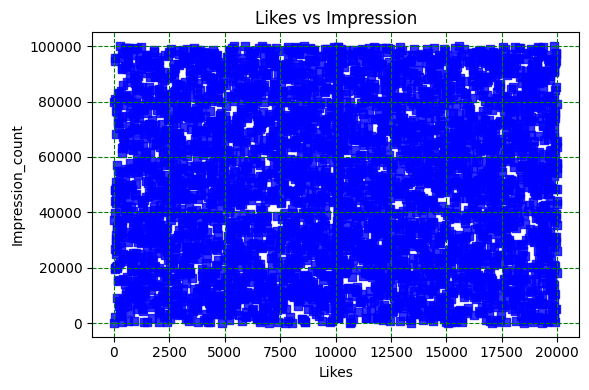

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.scatter(data['Likes'],data['Impression_count'],
            color = 'blue',
            marker = 's',
            alpha = 0.8
            )
plt.title("Likes vs Impression")
plt.xlabel("Likes")
plt.ylabel("Impression_count")
plt.grid(True, linestyle = '--', color = 'green')
plt.tight_layout()
plt.show()



###Line: daily engagement trend

In [ ]:
daily_eng_trend = data.groupby('Posted_at')['Engagement_rate'].mean().reset_index()


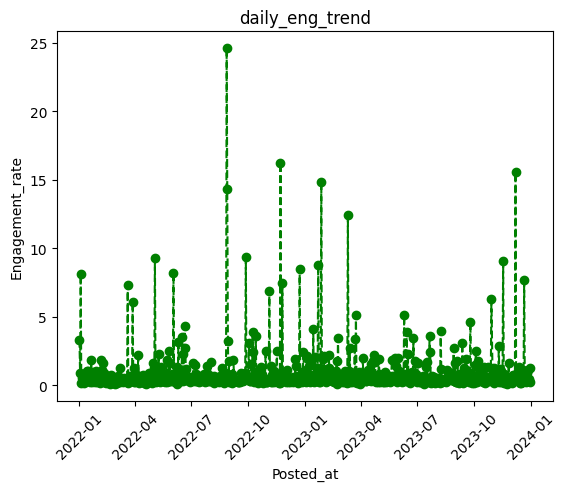

In [ ]:
plt.plot(daily_eng_trend['Posted_at'],
         daily_eng_trend['Engagement_rate'],
         color = 'green',
         marker = 'o',
         linestyle = '--')
plt.title("daily_eng_trend")
plt.xlabel('Posted_at')
plt.ylabel('Engagement_rate')
plt.xticks(rotation =45)
plt.show()

###Histogram: age

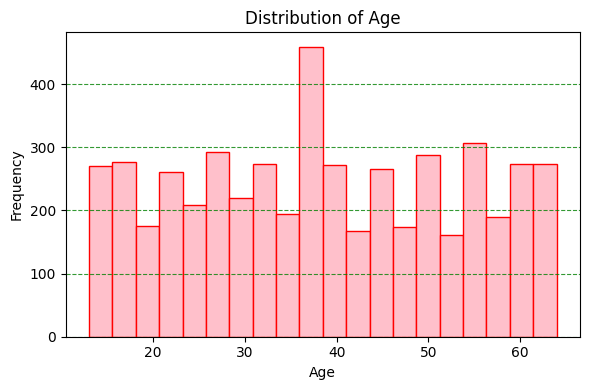

In [ ]:
plt.figure(figsize=(6,4))

plt.hist(data['Age'],
         bins = 20,
         color = 'pink',
         edgecolor = 'red')
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha = 0.8, color ='green')
plt.show()


###Box: engagement rate

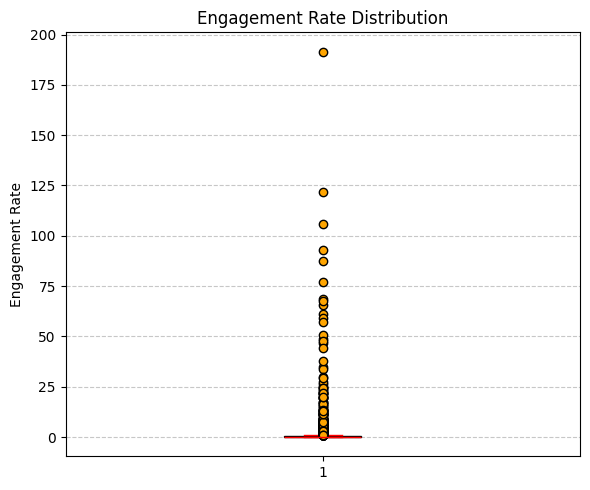

In [ ]:
plt.figure(figsize=(6, 5))


plt.boxplot(data["Engagement_rate"],
            patch_artist= True,
            boxprops    = dict(facecolor='lightgreen',color='black'),
            medianprops = dict(color='red'),
            whiskerprops= dict(color='yellow'),
            capprops    = dict(color='red'),
            flierprops  = dict(marker='o',markerfacecolor='orange'))



plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Distribution')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

##Seaborn
###Count plot: post type

/tmp/ipykernel_57098/2088549363.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Post_type",


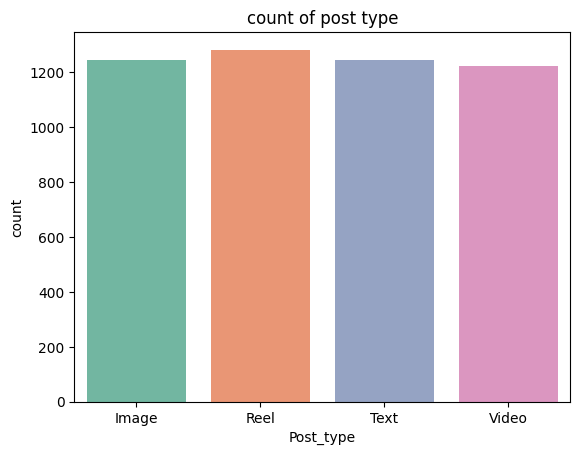

In [ ]:
import seaborn as sns

sns.countplot(x="Post_type",
              data = data,
              palette= 'Set2')
plt.title("count of post type")
plt.show()

###Bar plot: avg likes by category

/tmp/ipykernel_57098/765566583.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Post_category",


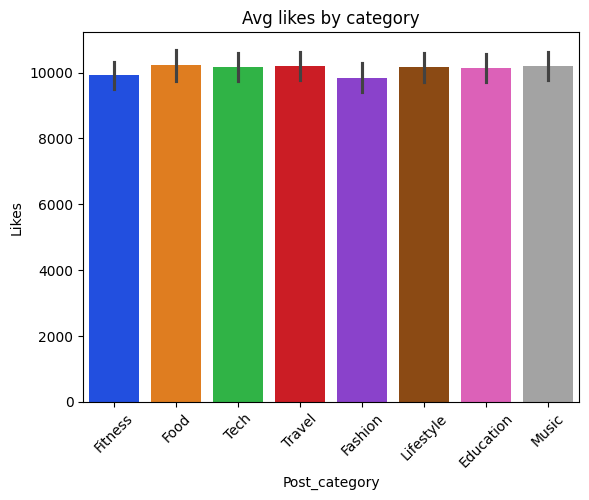

In [ ]:
sns.barplot(x="Post_category",
            y="Likes",
            data = data,
            estimator="mean",
            palette='bright'
            )
plt.title("Avg likes by category")
plt.xticks(rotation = 45)
plt.show()

###Violin: followers vs sentiment

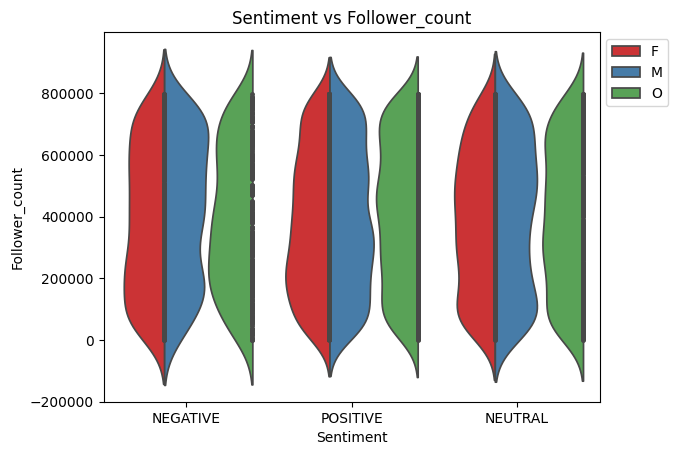

In [ ]:
from matplotlib.patches import bbox_artist
sns.violinplot(x="Sentiment",
               y= "Follower_count",
               hue = "Gender",
               data = data,
               split = 1,
               inner="point",
               palette= 'Set1')
plt.title("Sentiment vs Follower_count")
plt.legend(bbox_to_anchor=(1,1))
plt.show()


###Pair plot: numeric features

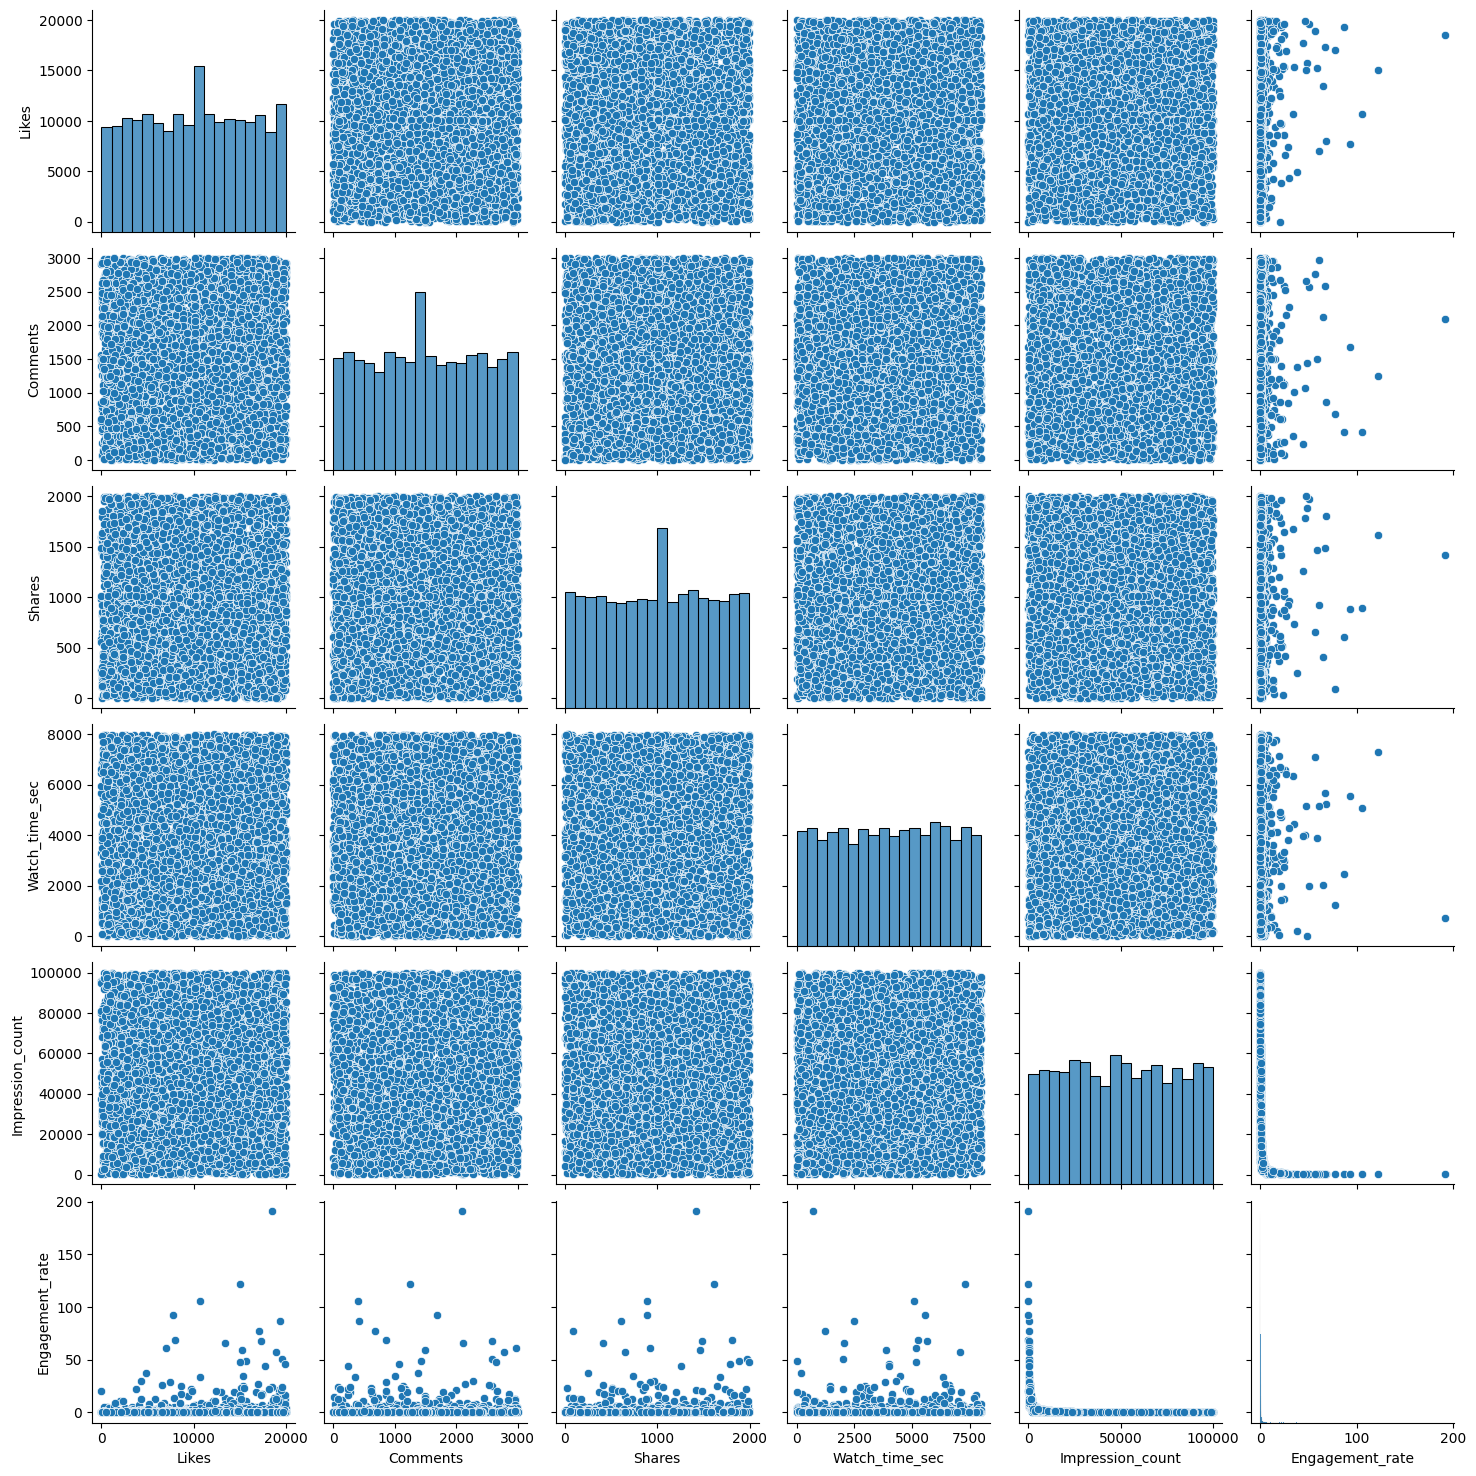

In [ ]:
numeric_columns =['Likes', 'Comments', 'Shares', 'Watch_time_sec', 'Impression_count', 'Engagement_rate']

sns.pairplot(data[numeric_columns])


plt.show()

###Heatmap: correlation matrix

In [ ]:
corr_matrix

,User_id,Age,Post_id,Likes,Comments,Shares,Watch_time_sec,Impression_count,Follower_count,Engagement_rate,Hashtag_count
User_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
Age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
Post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
Likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093521,-0.002190
Comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
Shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
Watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
Impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
Follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
Engagement_rate,-0.004282,0.008039,0.010139,0.093521,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


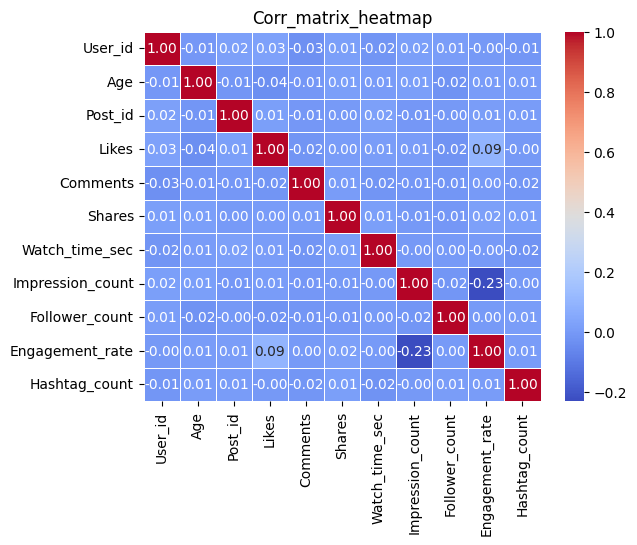

In [ ]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Corr_matrix_heatmap")
plt.show()

###Swarm plot: engagement vs device

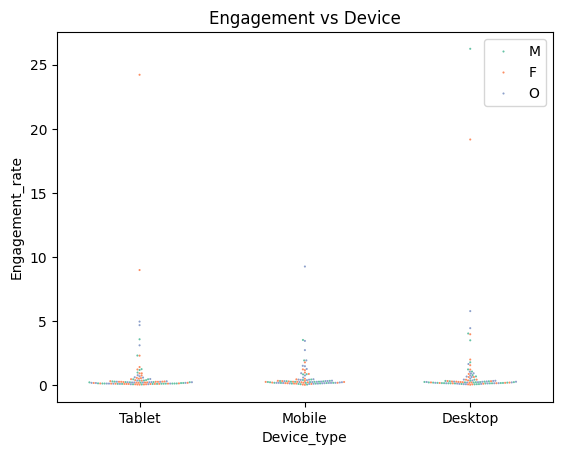

In [ ]:
sns.swarmplot(x="Device_type",
              y="Engagement_rate",
              hue= "Gender",
              data = data.sample(300, random_state=1),
              size = 1.5,
              palette= 'Set2')
plt.title("Engagement vs Device")
plt.legend(bbox_to_anchor=(1,1))
plt.show()

#Final Insights should include the following analysis:


In [ ]:
# ============ 1. CONTENT PERFORMANCE ============

# Which post types have highest engagement?
print("Engagement by Post Type:\n", data.groupby('Post_type')['engagement_score'].mean().sort_values(ascending=False))

# Best-performing content category
print("\nEngagement by Category:\n", data.groupby('Post_category')['engagement_score'].mean().sort_values(ascending=False))

# Countries with highest average engagement rate
print("\nEngagement Rate by Country:\n", data.groupby('Country')['Engagement_rate'].mean().sort_values(ascending=False))




Engagement by Post Type:
 Post_type
Video    12664.580408
Image    12649.377706
Text     12613.228112
Reel     12524.014030
Name: engagement_score, dtype: float64

Engagement by Category:
 Post_category
Music        12788.537008
Food         12739.180438
Tech         12686.479699
Travel       12650.545000
Lifestyle    12639.517298
Education    12578.255151
Fitness      12457.780741
Fashion      12356.405724
Name: engagement_score, dtype: float64

Engagement Rate by Country:
 Country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: Engagement_rate, dtype: float64


In [ ]:
# ============ 2. USER TRENDS ============

# How age affects engagement (correlation + bucket-wise average)
data['age_group'] = pd.cut(data['Age'], bins=[0,18,25,35,45,60,100],
                             labels=['<18','18-25','26-35','36-45','46-60','60+'])
print("\nEngagement by Age Group:\n", data.groupby('age_group')['engagement_score'].mean())

# Verified vs non-verified accounts performance
print("\nEngagement: Verified vs Non-verified:\n", data.groupby('Is_verified')['engagement_score'].mean())




Engagement by Age Group:
 age_group
<18      12991.697802
18-25    12628.395963
26-35    12768.689093
36-45    12741.565056
46-60    12318.692197
60+      12326.373984
Name: engagement_score, dtype: float64

Engagement: Verified vs Non-verified:
 Is_verified
False    12644.296436
True     12309.269151
Name: engagement_score, dtype: float64


/tmp/ipykernel_57098/3626218603.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("\nEngagement by Age Group:\n", data.groupby('age_group')['engagement_score'].mean())


In [ ]:
# ============ 3. BEHAVIORAL INSIGHTS ============

# Best time of day for impressions (if posted_at has time component)
data['post_hour'] = data['Posted_at'].dt.hour
print("\nImpressions by Hour:\n", data.groupby('post_hour')['Impression_count'].mean().sort_values(ascending=False))

# Device type impact on watch time
print("\nWatch Time by Device:\n", data.groupby('Device_type')['Watch_time_sec'].mean().sort_values(ascending=False))




Impressions by Hour:
 post_hour
0    50013.7328
Name: Impression_count, dtype: float64

Watch Time by Device:
 Device_type
Mobile     4087.830760
Tablet     3979.736429
Desktop    3974.792521
Name: Watch_time_sec, dtype: float64


In [ ]:
# ============ 4. SENTIMENT ANALYSIS ============

# Which sentiment performs best
print("\nEngagement by Sentiment:\n", data.groupby('Sentiment')['engagement_score'].mean().sort_values(ascending=False))

# Behavior of negative/neutral posts (likes, comments, shares)
print("\nNegative/Neutral Sentiment Behavior:\n",
      data[data['Sentiment'].isin(['NEGATIVE','NEUTRAL'])].groupby('Sentiment')[['Likes','Comments','Shares']].mean())


Engagement by Sentiment:
 Sentiment
NEGATIVE    12731.483333
POSITIVE    12665.784322
NEUTRAL     12448.149312
Name: engagement_score, dtype: float64

Negative/Neutral Sentiment Behavior:
                   Likes     Comments       Shares
Sentiment                                        
NEGATIVE   10208.081250  1516.094792  1007.307292
NEUTRAL     9923.180092  1528.404060   996.565160
